# Machine Learning Calibration of Low-cost Gas Sensors for Factory CO Monitoring 

Inspired by: Delta Electronics Manufacturing Line Visit 

# Executive Summary

Taking inspiration from the screens on the ceiling showing air quality and noise levels in the Delta Electronics manufacturing line, this project covers a machine learning model that allows cheaper gas sensors to be used to estimate what a certified analyser would read. Certified analysers are used to monitor air quality in factories to ensure worker safety. Smaller companies might not be able to afford expensive analysers and may therefore be forced to use less accurate and less reliable sensors instead. Thus, worker safety is directly impacted, and this project aims to address this through the use of an ML model.

The UCI Air Quality Dataset (ID 360) was used. It contains 9,357 hourly records, of which 7,344 remained after cleaning. Five features relating to air quality and three related to weather were selected from each record. In this report, four regression models were trained and compared: Linear Regression, K-Nearest Neighbours, Decision Tree Regressor, and Random Forest Regressor.

The initial target for the prediction was C6H6 (benzene), but upon exploring the data it was found that C6H6 had a suspiciously strong relationship with one of the sensor readings. Consequently, the Decision Tree Regressor achieved an R^2 value that rounded to 1.000.

To avoid producing a misleading result, the prediction target was switched to CO (carbon monoxide) instead and the best model was found to be an optimised Random Forest Regressor with 300 decision trees and a maximum depth of 20. After being retrained using both the training and validation data, its predictions had an average absolute error of about 0.366 mg/m^3 (MAE), an RMSE of 0.535 mg/m^3 and an R^2 value of 0.830 on the test data. However, at higher concentrations, it still tended to underestimate. Since high CO concentrations are dangerous, an underestimate could be deadly. As such, this is proposed as an indicative monitoring system and a supplement to certified analysers to cover more area at a lower cost, rather than as a replacement.

# Selected Engineering Problem

During our visit to the Delta Electronics manufacturing line, I noticed large screens on the ceiling which were displaying live measurements of air quality and noise. These help to maintain worker safety because when something goes wrong with industrial machinery or manufacturing processes, toxic gases may be released. CO is one common gas hazard because it can be produced when materials do not burn completely, such as during a fire caused by equipment failure. CO is a toxic gas and it is also colourless and odourless, meaning gas sensors are needed to detect it and warn workers.

The selected engineering problem is the limited coverage of accurate CO monitoring across factory floors. Certified analysers, which have the capability to measure gases like CO, tend to be extremely expensive while still only being able to cover the area around each unit. This means that, to cover a complete factory floor, a company would need to buy many units. Companies with smaller budgets might not be able to afford this, and thus have to rely on cheaper sensors that produce less reliable readings and are affected by temperature and humidity. This could put human lives at risk.

If an ML model were to be able to close the gap between the cheaper sensors and the more accurate analysers, worker safety could be improved by making monitoring equipment more affordable and thus more widespread. Such a model would take cheap sensor readings along with environmental conditions like temperature and humidity as inputs, and estimate what the certified analyser would have read. The intended outcome is to help detect dangerous CO levels across the factory floor and give workers more time to take protective actions. The model would supplement certified analysers rather than replace them.

# Data Requirements and Assumptions

In order to estimate what the certified analyser would read using the cheaper sensors' data, the ML model needs to train on: the raw sensor readings, CO readings from a certified analyser at the same time, location and conditions, and the temperature and humidity measurements so that the model can handle different environmental conditions.

The UCI Air Quality Dataset (ID 360; De Vito, 2008) was selected as the training dataset because it has hourly averaged readings from multiple different sensors and certified analyser measurements for an entire year. It also has the temperature and humidity readings needed, and since the data is from outdoor sensors in Italy, these cover a wide range of conditions across seasons.

The final model takes in 8 inputs: the five PT08 sensor readings, temperature, relative humidity, and absolute humidity. The prediction target is CO(GT), which contains the certified analyser CO measurements. The data was split without shuffling since sensor readings are time-dependent.

However, the raw data still needed to be processed before use. Firstly, the dataset coded missing values as -200 which pandas does not handle as missing. So every instance of -200 needed to be replaced with NaN. Secondly, the columns containing the ground truth values, the certified analyser values, for the non-CO gases such as NO2 needed to be dropped since they were not readings from the sensors and thus could not be used as inputs to train the ML model on. The NMHC(GT) column was missing 8443 out of 9357 entries (~90% missing), which meant that it was completely unusable for this project, so it was dropped as well. Lastly, the instruments had failed readings and these happened at different times leading to rows with partial data, and trimming them brought the row count down from 9357 to 7344.

One potential issue with an ML model like this is that cheap sensors tend to drift over time. They can drift at an unknown rate and this drift would compound, causing the predictions to become less accurate over time. In order to account for this, the ML model would need to be retrained periodically or the sensors would need to be zeroed regularly.

The proposed solution makes the following assumptions: The certified analyser readings are accurate as the ground truth, the remaining 7344 readings are sufficient for a proof of concept, and the training data is sufficient to demonstrate the concept even though it may not fully represent factory deployment conditions. A real deployment would require factory-specific data.

# Proposed AI/ML Solution Design

## Proposed System Workflow

The model uses the five PT08 sensor readings, temperature, relative humidity and absolute humidity as inputs. The data is first cleaned and then split into training, validation and testing sets. 

Multiple regression models are then trained and compared using this data, after which the best-performing model is selected to estimate the CO concentration to display as an indicative reading to factory workers or safety staff.

## Model Selection and Justification

The prediction target, CO(GT), is a numerical value rather than a category. As such, regression models were used, and multiple regression models were compared since the relationship between sensor readings, environmental conditions and CO concentration might not be completely linear.

In case the relationship was linear, Linear Regression was selected as the simplest model. K-Nearest Neighbours was selected because sensor readings that are similar to each other might also have similar CO concentrations. The Decision Tree Regressor was chosen because it is capable of learning more complex non-linear relationships by splitting data into different conditions. The Random Forest Regressor was tested because it combines multiple decision trees making its predictions potentially more reliable with reduced overfitting.

Ridge Regression was also tested during model optimisation because several of the sensor readings were strongly related to each other. The final model selected would be the one with the best performance on the validation data before being tested on the final test set.

## Data Preparation and Exploration

The UCI Air Quality Dataset was first loaded and the first five rows were displayed to make sure that the data and columns had been imported correctly.

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

air_quality = fetch_ucirepo(id=360)
df = air_quality.data.features.copy()

print(df.shape)
df.head()

(9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


The original dataset contains 9,357 rows and 15 columns.

Check the number of missing values in each column. This dataset represents missing readings using -200 instead of NaN, so the number of -200 values in each column was counted.

In [ ]:
(df == -200).sum()

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

The results showed that several columns contained missing values, with NMHC(GT) missing 8,443 out of 9,357 readings.

Replace -200 with NaN so that pandas can handle the missing data

In [ ]:
import numpy as np

df = df.replace(-200, np.nan) # -200 is this dataset's code for missing


Generate a basic summary of the data to identify any unusual values easily.

Since the PT08 columns contain sensor readings, a correlation heatmap was used to check how strongly each sensor was related to CO(GT). A stronger correlation suggests that the sensor may be useful for predicting CO even though correlation mainly shows linear relationships.

        CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
count  7674.00      8991.00    914.00   8991.00        8991.00  7718.00   
mean      2.15      1099.83    218.81     10.08         939.15   246.90   
std       1.45       217.08    204.46      7.45         266.83   212.98   
min       0.10       647.00      7.00      0.10         383.00     2.00   
25%       1.10       937.00     67.00      4.40         734.50    98.00   
50%       1.80      1063.00    150.00      8.20         909.00   180.00   
75%       2.90      1231.00    297.00     14.00        1116.00   326.00   
max      11.90      2040.00   1189.00     63.70        2214.00  1479.00   

       PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)        T       RH  \
count       8991.00  7715.00       8991.00      8991.00  8991.00  8991.00   
mean         835.49   113.09       1456.26      1022.91    18.32    49.23   
std          256.82    48.37        346.21       398.48     8.83    17.32   
min          322

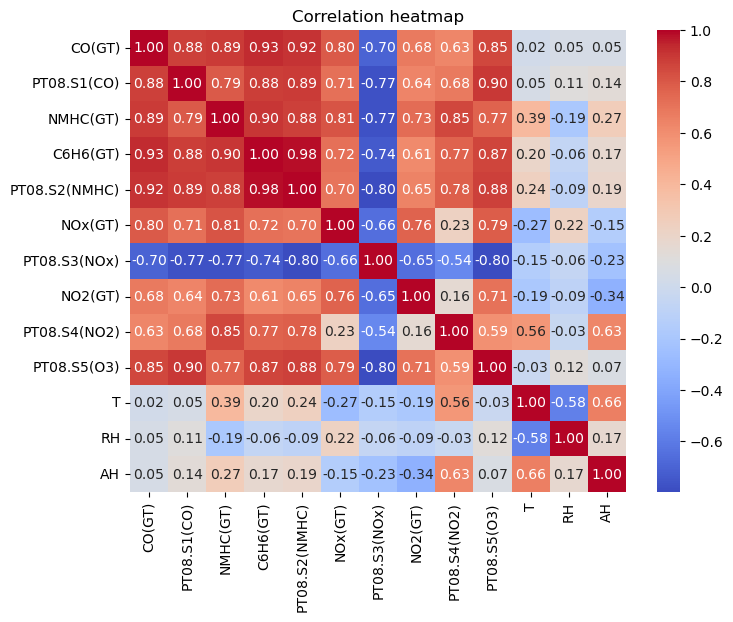

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.describe().round(2))

# correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=["Date", "Time"]).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

C6H6 was selected as the first prediction target because it was the original research target of the dataset, and it had a correlation of 0.98 with PT08.S2. However, when initial testing of the models was performed, the Decision Tree Regressor achieved an R^2 value that rounded to 1.000. Since this was a suspiciously good result, the readings of PT08.S2 and the values of C6H6 were plotted to see what their relationship was.

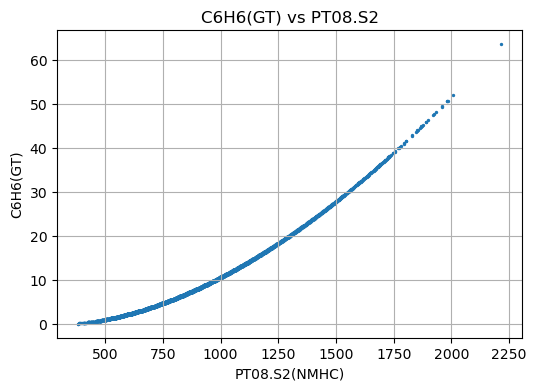

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df["PT08.S2(NMHC)"], df["C6H6(GT)"], s=2)
plt.xlabel("PT08.S2(NMHC)")
plt.ylabel("C6H6(GT)")
plt.title("C6H6(GT) vs PT08.S2")
plt.grid(True)
plt.show()

The scatter plot showed that the points followed an almost exact curve with nearly no visible scatter around it. This was a suspiciously strong relationship, and its cause could not be confirmed from the dataset information. As such, the decision to switch to CO was made.

After CO was selected as the prediction target, the certified analyser readings for the other gases were dropped since they could not be used as model inputs. Rows that still contained missing values were also removed.

In [ ]:
df = df.drop(columns=["NMHC(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"])

# drop every row that still has any missing value
df = df.dropna()

print(df.shape)
print(df.isna().sum())


(7344, 11)
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
PT08.S2(NMHC)    0
PT08.S3(NOx)     0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


The five PT08 sensor readings, temperature, relative humidity and absolute humidity were selected as the eight model inputs, while CO(GT) was selected as the prediction target.

In [ ]:
feature_cols = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)",
                "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]

X = df[feature_cols]
#y = df["C6H6(GT)"]
y = df["CO(GT)"]

print(X.shape, y.shape)

(7344, 8) (7344,)


After removing the unnecessary columns and incomplete rows, 7,344 complete records remained with no missing values. 

The input data, X, has a shape of (7,344, 8) for its 7,344 records with eight inputs each. The target data, y, contains one CO value for each of the 7,344 records.

The data was split into training, validation and testing sets without shuffling because the readings are time-dependent.

In [ ]:
from sklearn.model_selection import train_test_split

# Last 20% for test
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Split the first 80% into 60% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split( X_trainval, y_trainval, test_size=0.25, shuffle=False)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (4406, 8)
Validation: (1469, 8)
Test: (1469, 8)


## Model Training and Comparison

The four selected regression models were trained using the training data and compared using the validation data. The same training and validation data were used for every model for a fair comparison, and RMSE, MAE and R^2 were used to measure their performance. Lower RMSE and MAE values and a higher R^2 value show better predictions.

### Linear Regression

Linear Regression was trained using the training data before its predictions were evaluated using the validation data.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

LR = LinearRegression()
LR.fit(X_train, y_train)

y_pred = LR.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"Linear Regression  RMSE: {rmse:.3f}  MAE: {mae:.3f}  R2: {r2:.3f}")

Linear Regression  RMSE: 0.794  MAE: 0.554  R2: 0.785


### Data Scaling

KNN calculates the distance between different readings, so inputs with larger values could affect the result more. StandardScaler was therefore fitted using the training data and then applied to the validation and testing data.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(X_train_s.mean().round(3), X_train_s.std().round(3))

0.0 1.0


### K-Nearest Neighbours

KNN was trained using a starting k value of 5, and its predictions were evaluated using the scaled validation data.

In [ ]:
# KNN
from sklearn.neighbors import KNeighborsRegressor

KNN = KNeighborsRegressor(n_neighbors=5) # set hyperparameter to 5
KNN.fit(X_train_s, y_train)

y_pred = KNN.predict(X_val_s)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"KNN (k=5)  RMSE: {rmse:.3f}  MAE: {mae:.3f}  R2: {r2:.3f}")

KNN (k=5)  RMSE: 0.845  MAE: 0.577  R2: 0.757


### Decision Tree Regressor

The Decision Tree Regressor was first trained with a maximum depth of 8 before being evaluated using the validation data.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

DT = DecisionTreeRegressor(max_depth=8, random_state=42) 
DT.fit(X_train, y_train)

y_pred = DT.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"Decision Tree (depth=8)  RMSE: {rmse:.3f}  MAE: {mae:.3f}  R2: {r2:.3f}")

Decision Tree (depth=8)  RMSE: 0.790  MAE: 0.540  R2: 0.788


### Random Forest Regressor

The Random Forest Regressor was trained using 200 decision trees before being evaluated using the validation data.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

RF = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1) # n_jobs = -1 --> use all CPU cores
RF.fit(X_train, y_train)

y_pred = RF.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"Random Forest  RMSE: {rmse:.3f}  MAE: {mae:.3f}  R2: {r2:.3f}")

Random Forest  RMSE: 0.716  MAE: 0.470  R2: 0.826


These results show the initial performance of each model before optimisation. KNN, Decision Tree, Ridge Regression and Random Forest are tested further in the next section.

## Model Optimization

### Ridge Regression Optimisation

Different alpha values were tested to see whether adding regularisation could improve Linear Regression. Each alpha value was compared using its RMSE on the validation data.

In [ ]:
from sklearn.linear_model import Ridge

alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
rmse_list = []

for a in alphas:
    model = Ridge(alpha=a)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_val_s)
    rmse_list.append(np.sqrt(mean_squared_error(y_val, pred)))

for a, r in zip(alphas, rmse_list):
    print(f"alpha={a:>7}  RMSE={r:.3f}")

alpha=  0.001  RMSE=0.794
alpha=   0.01  RMSE=0.794
alpha=    0.1  RMSE=0.794
alpha=      1  RMSE=0.794
alpha=     10  RMSE=0.792
alpha=    100  RMSE=0.793
alpha=   1000  RMSE=0.851


### KNN Optimisation

Different odd k values from 1 to 99 were compared using their RMSE on the validation data in order to find the best number of neighbours.

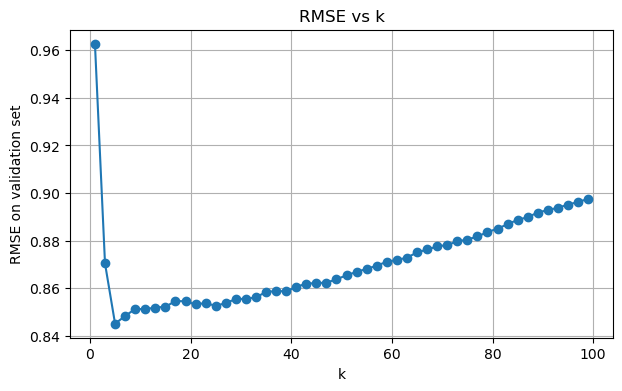

Best k = 5, RMSE = 0.845


In [ ]:
k_values = range(1, 101, 2)
rmse_list = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_val_s)
    rmse_list.append(np.sqrt(mean_squared_error(y_val, pred)))

plt.figure(figsize=(7, 4))
plt.plot(k_values, rmse_list, marker="o")
plt.xlabel("k")
plt.ylabel("RMSE on validation set")
plt.title("RMSE vs k")
plt.grid(True)
plt.show()

best_k = k_values[int(np.argmin(rmse_list))]
print(f"Best k = {best_k}, RMSE = {min(rmse_list):.3f}")

### Decision Tree Optimisation

Different maximum depths from 1 to 20 were tested to find how deep the Decision Tree should be. Each depth was compared using its RMSE on the validation data.

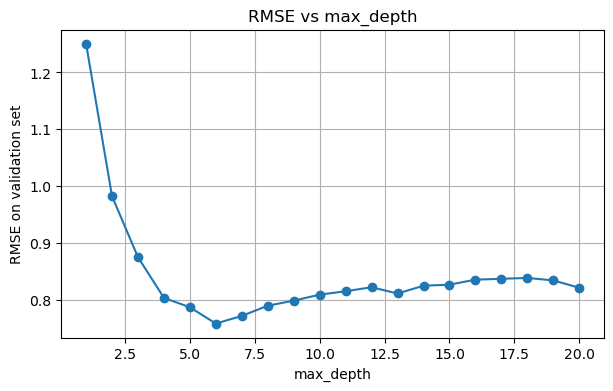

Best depth = 6, RMSE = 0.759


In [ ]:
depths = range(1, 21)
rmse_list = []

for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rmse_list.append(np.sqrt(mean_squared_error(y_val, pred)))

plt.figure(figsize=(7, 4))
plt.plot(depths, rmse_list, marker="o")
plt.xlabel("max_depth")
plt.ylabel("RMSE on validation set")
plt.title("RMSE vs max_depth")
plt.grid(True)
plt.show()

best_d = depths[int(np.argmin(rmse_list))]
print(f"Best depth = {best_d}, RMSE = {min(rmse_list):.3f}")

### Random Forest Optimisation

Since Random Forest had the best initial validation results, the number of decision trees and maximum tree depth were tested further. Each combination was compared using its RMSE on the validation data.

In [ ]:
n_estimators_values = [50, 100, 200, 300, 500]
max_depth_values = [None, 5, 10, 15, 20]

rf_results = []
best_rf_rmse = float("inf")
best_rf_params = None

for n in n_estimators_values:
    for depth in max_depth_values:
        model = RandomForestRegressor(
            n_estimators=n,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)
        pred = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, pred))
        rf_results.append([n, depth, rmse])

        if rmse < best_rf_rmse:
            best_rf_rmse = rmse
            best_rf_params = {
                "n_estimators": n,
                "max_depth": depth
            }

rf_results_df = pd.DataFrame(
    rf_results,
    columns=["n_estimators", "max_depth", "RMSE"]
)

display(rf_results_df.sort_values("RMSE"))

print("Best settings:", best_rf_params)
print(f"Best validation RMSE: {best_rf_rmse:.3f}")

,n_estimators,max_depth,RMSE
19,300,20.0,0.715549
24,500,20.0,0.715715
14,200,20.0,0.715762
12,200,10.0,0.715871
17,300,10.0,0.715897
7,100,10.0,0.715945
10,200,NaN,0.715950
15,300,NaN,0.716345
23,500,15.0,0.716408
22,500,10.0,0.716447


Best settings: {'n_estimators': 300, 'max_depth': 20}
Best validation RMSE: 0.716


Ridge Regression very slightly improved the Linear Regression RMSE from 0.794 to 0.792, with an alpha of 10.

Changing the k value did not improve KNN. Its best result remained at k=5 and RMSE of 0.845. 

Decision Tree Regressor's maximum depth being reduced from 8 to 6 improved its RMSE from 0.790 to 0.759. 

Random Forest still had the lowest validation RMSE, with its best settings being 300 decision trees and a maximum depth of 20. 
As such, Random Forest was selected as the final model.

| Model | Best settings | Validation RMSE |
|---|---|---:|
| Linear Regression | No optimisation | 0.794 |
| Ridge Regression | Alpha = 10 | 0.792 |
| K-Nearest Neighbours | k = 5 | 0.845 |
| Decision Tree Regressor | Maximum depth = 6 | 0.759 |
| Random Forest Regressor | 300 trees, maximum depth = 20 | 0.716 |

# Evaluation Strategy

The model with the lowest RMSE on validation data is the optimised Random Forest Regressor, so it was selected as the final model. It was then retrained using both the training and validation data before being evaluated using the test data. RMSE, MAE and R^2 were used again to measure how well the final model performed on data that was not used for training or model selection.

In [ ]:
final_RF = RandomForestRegressor( n_estimators=300, max_depth=20, random_state=42, n_jobs=-1)

# Retrain using the combined training and validation data
final_RF.fit(X_trainval, y_trainval)

# Evaluate using the test data
y_test_pred = final_RF.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Final Random Forest RMSE: {test_rmse:.3f}")
print(f"Final Random Forest MAE: {test_mae:.3f}")
print(f"Final Random Forest R2: {test_r2:.3f}")

Final Random Forest RMSE: 0.535
Final Random Forest MAE: 0.366
Final Random Forest R2: 0.830


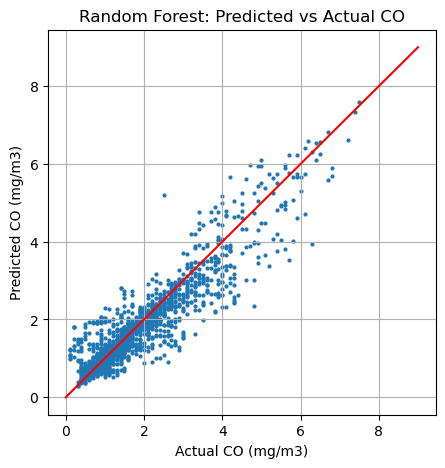

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_test_pred, s=4)
plt.plot([0, 9], [0, 9], color="red")

plt.xlabel("Actual CO (mg/m3)")
plt.ylabel("Predicted CO (mg/m3)")
plt.title("Random Forest: Predicted vs Actual CO")
plt.grid(True)
plt.show()

The final Random Forest Regressor was retrained using both the training and validation data, and it achieved an RMSE of 0.535 mg/m³, MAE of 0.366 mg/m^3 and R^2 value of 0.830 on the test data. Most of the points being close to the red line shows that the predictions were generally close to the actual readings. However at higher CO concentrations more and more points fell below the red line, which means that it tends to underestimate the readings. This could be dangerous since the system could report a safe reading even if the actual reading is above the safe threshold.

## Limitations and Risks

There are several limitations to the proposed solution. First of all, the UCI dataset contains data from sensors placed outdoors in an Italian city, and not from inside a factory. This means that the conditions may not be representative of the intended deployment environment. The readings are also hourly averages so a sudden CO leak might go undetected. Additionally, cheap gas sensors can drift over time, causing the model’s predictions to become less accurate unless the sensors are regularly recalibrated and the model is retrained using newer data.

The main risk is that the model tends to underestimate readings at higher CO concentrations, and this means the warning could come too late for workers. Overestimating the concentration would cause more false alarms affecting production, but it's safer than missing a dangerous CO level. Therefore, the warning threshold should favour safety while still keeping false alarms at a reasonable level.

# Conclusion

This project investigated whether readings from cheaper gas sensors could be used to estimate the CO measurements from a certified analyser. During data exploration, C6H6 was found to have a suspiciously strong relationship with one of the sensor readings, so the prediction target was changed to CO to avoid producing a misleading result.

Four regression models were trained and compared and the best result was achieved by Random Forest Regression. The results were further improved by optimising the Random Forest Regression with 300 decision tree models and a maximum depth of 20. On the test data, it achieved an RMSE of 0.535 mg/m³, an MAE of 0.366 mg/m³ and an R² value of 0.830. This shows that the cheap sensor readings contained enough information to produce reasonably accurate CO estimates.  

However the model tended to underestimate higher CO concentrations and was trained on outdoor data from Italy, not the actual factory data. Therefore the model should not be used as a replacement for certified monitoring equipment, but it could be used as an indicative monitoring system or as a supplement to provide a wider coverage at a lower cost. Future improvements would require data collected from the intended factory environment, along with regular sensor recalibration and model retraining.

# References

De Vito, S. (2008). *Air quality* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C59K5F

Matplotlib development team. (n.d.). *matplotlib.pyplot.scatter*. Matplotlib documentation. Retrieved August 8, 2026, from https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html

Mayo Clinic Staff. (2025, March 28). *Carbon monoxide poisoning*. https://www.mayoclinic.org/diseases-conditions/carbon-monoxide/symptoms-causes/syc-20370642

pandas development team. (n.d.). *pandas.DataFrame.corr*. pandas documentation. Retrieved August 8, 2026, from https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html

scikit-learn developers. (n.d.-a). *DecisionTreeRegressor*. scikit-learn documentation. Retrieved August 8, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

scikit-learn developers. (n.d.-b). *Metrics and scoring: Quantifying the quality of predictions*. scikit-learn documentation. Retrieved August 8, 2026, from https://scikit-learn.org/stable/modules/model_evaluation.html

scikit-learn developers. (n.d.-c). *RandomForestRegressor*. scikit-learn documentation. Retrieved August 8, 2026, from https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

Waskom, M. (n.d.). *seaborn.heatmap*. seaborn. Retrieved August 8, 2026, from https://seaborn.pydata.org/generated/seaborn.heatmap.html